# Módulo 8 — Fourier II: Carr-Madan, FFT e convolução

**Curso:** Derivativos com Python, a partir de *Derivatives Analytics with Python* (Y. Hilpisch, Wiley, 2015).
**Este módulo cobre:** seções 6.4.2 a 6.6 do livro.

## O que você vai conseguir fazer ao final

1. Deduzir a fórmula de Carr-Madan e ver que ela é a fórmula de Lewis em outra reta.
2. Escolher o parâmetro de amortecimento $\alpha$.
3. Tratar opções muito fora do dinheiro com a transformada do valor no tempo.
4. Entender a transformada discreta, as raízes da unidade e o algoritmo FFT.
5. Precificar uma grade inteira de strikes com FFT, e saber quando isso compensa.
6. Ver a árvore binomial como uma convolução.

## 0. Preparação

In [1]:
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import simpson
from scipy.interpolate import CubicSpline
from scipy.optimize import minimize_scalar
from scipy.stats import norm, poisson
from IPython.display import display

AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a84"

plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "lines.linewidth": 2.0, "legend.frameon": False,
    "font.size": 10,
})


def f3(x):
    """Formata com três casas decimais no padrão brasileiro."""
    return f"{x:,.3f}".replace(",", "§").replace(".", ",").replace("§", ".")


def tabela(df):
    """Exibe um DataFrame com os números reais em três casas decimais."""
    def fmt(v):
        if isinstance(v, (float, np.floating)):
            return "n/d" if np.isnan(v) else f3(v)
        return v
    display(df.map(fmt))


_checks = {"n": 0}


def ok(condicao, mensagem):
    """Verificação do laboratório: interrompe o notebook se a conta não fechar."""
    assert bool(condicao), f"FALHOU: {mensagem}"
    _checks["n"] += 1
    print(f"OK — {mensagem}")


def bsm(S, K, T, r, sig, tipo="call"):
    d1 = (np.log(S / K) + (r + 0.5 * sig**2) * T) / (sig * np.sqrt(T))
    d2 = d1 - sig * np.sqrt(T)
    if tipo == "call":
        return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)


def cf_bsm(u, T, sigma):
    """Função característica de X_T, parte martingale do log-retorno."""
    return np.exp(-0.5 * sigma**2 * T * (1j * u + u**2))


def cf_merton(u, T, sigma, lam, mu, delta):
    omega = -0.5 * sigma**2 - lam * (np.exp(mu + 0.5 * delta**2) - 1)
    return np.exp(T * (1j * u * omega - 0.5 * sigma**2 * u**2 + lam * (np.exp(1j * u * mu - 0.5 * u**2 * delta**2) - 1)))


def lewis(S, K, T, r, cf, U, n):
    K = np.atleast_1d(np.asarray(K, float))
    k = np.log(S / K) + r * T
    z = np.linspace(0.0, U, n)
    h = np.exp(1j * z * k[:, None]) * cf(z - 0.5j)
    return S - np.sqrt(S * K) * np.exp(-0.5 * r * T) / np.pi * simpson(h.real / (z**2 + 0.25), x=z, axis=1)


S0, K0, T0, r0, s0 = 100.0, 100.0, 1.0, 0.05, 0.20
print("Ambiente pronto. Call BSM:", f3(float(bsm(S0, K0, T0, r0, s0))))

Ambiente pronto. Call BSM: 10,451


---
## 1. A abordagem de Carr-Madan

**Livro: §6.4.2**

### 1.1 Mudança de ponto de vista

Lewis transformou o payoff em relação ao log-preço. Carr e Madan (1999) transformam **o preço da opção em relação ao log-strike** $k = \ln K$. Se a integral for sobre os strikes, a inversão entrega o preço para muitos strikes simultaneamente, e é isso que permitirá usar a FFT.

### 1.2 O problema da integrabilidade

Quando $k \to -\infty$, a call tende a $S_0$, e não a zero. A função $C(k)$ não é integrável. A solução é amortecer:

$$c(k) = e^{\alpha k}\,C(k), \qquad \alpha > 0.$$

### 1.3 Dedução

Seja $s = \ln S_T$ e $q$ sua densidade. A transformada de $c$ é

$$\psi(v) = \int_{-\infty}^{\infty}e^{ivk}\,e^{\alpha k}\,e^{-rT}\int_k^\infty(e^s - e^k)\,q(s)\,ds\,dk.$$

**Passo 1: trocar a ordem (Fubini).** A região $\{s > k\}$ equivale a $k \in (-\infty, s)$:

$$\psi(v) = e^{-rT}\int_{-\infty}^{\infty}q(s)\Big[\int_{-\infty}^{s}e^{(iv+\alpha)k}\big(e^s - e^k\big)\,dk\Big]ds.$$

**Passo 2: integrar em $k$.** Como $\alpha > 0$, o limite inferior anula:

$$\int_{-\infty}^s e^{(iv+\alpha)k}(e^s - e^k)\,dk = e^s\frac{e^{(iv+\alpha)s}}{iv+\alpha} - \frac{e^{(iv+\alpha+1)s}}{iv+\alpha+1} = \frac{e^{(iv+\alpha+1)s}}{(iv+\alpha)(iv+\alpha+1)}.$$

**Passo 3: reconhecer a função característica.** Note que $e^{(iv+\alpha+1)s} = e^{i(v-(\alpha+1)i)s}$. Multiplicando o denominador:

$$\boxed{\psi(v) = \frac{e^{-rT}\,\phi_s\big(v - (\alpha+1)i\big)}{\alpha^2 + \alpha - v^2 + i(2\alpha+1)v}.}$$

**Passo 4: inverter.** Como $C(k)$ é real, a transformada satisfaz $\psi(-v) = \overline{\psi(v)}$, e

$$C(k) = \frac{e^{-\alpha k}}{\pi}\int_0^\infty\text{Re}\big[e^{-ivk}\psi(v)\big]\,dv.$$

(O livro omite o $\text{Re}$ na equação (6.6), mas ele é necessário.)

### 1.4 Quem é Carr-Madan, em relação a Lewis?

Observe o argumento de $\phi$: $v - (\alpha+1)i$. Compare com a integral de Lewis, $\phi(-u)$ em $u = z + iu_i$, com $u_i > 1$. Fazendo $u = -v + i(\alpha+1)$, **é a mesma integral, numa reta com $u_i = \alpha + 1$**. Carr-Madan é a fórmula original de Lewis antes de atravessar o polo em $u = i$, e com um nome diferente para $u_i$.

### 1.5 O parâmetro $\alpha$

Há duas restrições.

- **Limite superior:** $\phi_s(v - (\alpha+1)i)$ precisa existir, ou seja, $\mathbb{E}[S_T^{\alpha+1}] < \infty$. Em Heston, o momento pode explodir.
- **Precisão:** $\alpha$ pequeno deixa o integrando próximo do polo em $v = 0$; $\alpha$ grande amplifica $e^{-\alpha k}$.

Carr e Madan sugerem algo em torno de $\tfrac14$ do limite; o livro usa $\alpha = 1{,}5$.

### Laboratório 1.1 — Carr-Madan em uma reta só

In [2]:
def carr_madan(S, K, T, r, cf, alpha, U=400.0, n=40001):
    """Carr-Madan com integração direta. cf é a função característica de X_T."""
    K = np.atleast_1d(np.asarray(K, float))
    k = np.log(K / S)
    v = np.linspace(0.0, U, n)
    w = v - (alpha + 1) * 1j
    fi = np.exp(1j * w * r * T) * cf(w)
    psi = np.exp(-r * T) * fi / (alpha**2 + alpha - v**2 + 1j * (2 * alpha + 1) * v)
    return S * np.exp(-alpha * k) / np.pi * simpson((np.exp(-1j * v * k[:, None]) * psi).real, x=v, axis=1)


Kt = np.array([80.0, 100.0, 120.0])
ref = bsm(S0, Kt, T0, r0, s0)
cf_ = lambda u: cf_bsm(u, T0, s0)
linhas = []
for al in [0.1, 0.25, 0.5, 1.0, 1.5, 3.0, 6.0, 12.0, 25.0]:
    v = carr_madan(S0, Kt, T0, r0, cf_, al, U=80.0, n=1601)
    linhas.append({"α": al, "Erro K=80 (×10⁶)": abs(v[0] - ref[0]) * 1e6, "Erro K=100 (×10⁶)": abs(v[1] - ref[1]) * 1e6, "Erro K=120 (×10⁶)": abs(v[2] - ref[2]) * 1e6})
al_t = pd.DataFrame(linhas)
tabela(al_t)
v_fina = carr_madan(S0, Kt, T0, r0, cf_, 1.5)
v_lw = lewis(S0, Kt, T0, r0, cf_, 400.0, 40001)
print("Carr-Madan (α = 1,5):", [f3(float(x)) for x in v_fina], "| Lewis:", [f3(float(x)) for x in v_lw])

ok(np.max(np.abs(v_fina - ref)) < 1e-9 and np.max(np.abs(v_lw - ref)) < 1e-9, "Carr-Madan e Lewis coincidem com o BSM")
ok(al_t["Erro K=100 (×10⁶)"].iloc[0] > 10 * al_t["Erro K=100 (×10⁶)"].iloc[4], "α muito pequeno aumenta o erro, com a mesma malha")
ok(al_t["Erro K=100 (×10⁶)"].iloc[-1] > 10 * al_t["Erro K=100 (×10⁶)"].iloc[4], "α muito grande também aumenta o erro")

,α,Erro K=80 (×10⁶),Erro K=100 (×10⁶),Erro K=120 (×10⁶)
0,"0,100","61.899,573","61.899,573","61.899,573"
1,"0,250","5,023","5,023","5,023"
2,"0,500","0,000","0,000","0,000"
3,"1,000","0,000","0,000","0,000"
4,"1,500","0,000","0,000","0,000"
5,"3,000","0,000","0,000","0,000"
6,"6,000","0,000","0,000","0,000"
7,"12,000","0,000","0,000","0,000"
8,"25,000","0,001","0,000","0,000"


Carr-Madan (α = 1,5): ['24,589', '10,451', '3,247'] | Lewis: ['24,589', '10,451', '3,247']
OK — Carr-Madan e Lewis coincidem com o BSM
OK — α muito pequeno aumenta o erro, com a mesma malha
OK — α muito grande também aumenta o erro


### 1.6 Fora do dinheiro: transformar o valor no tempo

Vimos no Módulo 7 que uma call muito fora do dinheiro é obtida como a diferença de dois números grandes. Carr e Madan propõem transformar diretamente o **valor no tempo**, normalizado com $S_0 = 1$:

$$z(k) = \begin{cases}\text{put de strike } e^k, & k < 0,\\ \text{call de strike } e^k, & k > 0.\end{cases}$$

Sua transformada é

$$\varsigma(v) = e^{-rT}\Big(\frac{1}{1 + iv} - \frac{e^{rT}}{iv} - \frac{\phi_s(v - i)}{v^2 - iv}\Big).$$

Como $z$ tem pico em $k = 0$, um amortecimento $\sinh(\alpha k)$ ajuda:

$$\gamma(v) = \frac{\varsigma(v - i\alpha) - \varsigma(v + i\alpha)}{2}, \qquad z(k) = \frac{1}{\sinh(\alpha k)}\,\frac{1}{2\pi}\int_{-\infty}^{\infty}e^{-ivk}\gamma(v)\,dv.$$

**Mas há um custo.** Os dois primeiros termos de $\varsigma$ decaem apenas como $1/v$, e $\gamma$, como $1/v^2$, mesmo que $\phi$ caia rapidamente. Truncar a integral custa caro.

**Uma alternativa simples** é manter a transformada da call e escolher $\alpha$ **por strike**. Lord e Kahl propõem o valor que minimiza o módulo do integrando em $v = 0$, ou seja, que coloca a reta de integração perto do ponto de sela. Sem subtração de números grandes e sem cauda lenta.

### Laboratório 1.2 — Precisão em opções muito fora do dinheiro

Repetimos o caso difícil do Módulo 7: prazo de um mês, malha grossa ($U = 60$), strikes longe do dinheiro. Depois, repetimos a transformada OTM com $U = 1.000$.

In [3]:
def valor_tempo(S, K, T, r, cf, alpha=1.1, U=60.0, n=2001):
    """Valor no tempo pela transformada OTM de Carr-Madan (put se K<S, call se K>S)."""
    K = np.atleast_1d(np.asarray(K, float))
    k = np.log(K / S)
    v = np.linspace(-U, U, 2 * n - 1)

    def vs(w):
        w_i = w - 1j
        fi = np.exp(1j * w_i * r * T) * cf(w_i)
        return np.exp(-r * T) * (1 / (1 + 1j * w) - np.exp(r * T) / (1j * w) - fi / (w**2 - 1j * w))

    gama = 0.5 * (vs(v - 1j * alpha) - vs(v + 1j * alpha))
    integ = simpson((np.exp(-1j * v * k[:, None]) * gama).real, x=v, axis=1)
    return S * integ / (2 * np.pi * np.sinh(alpha * k))


Ks = np.array([110.0, 120.0, 130.0, 140.0, 150.0])
T_o, r_o, sig_o = 1 / 12, 0.03, 0.2
cf_o = lambda u: cf_bsm(u, T_o, sig_o)
ref = bsm(100.0, Ks, T_o, r_o, sig_o)
v_lewis = lewis(100.0, Ks, T_o, r_o, cf_o, 60.0, 2001)
v_otm = valor_tempo(100.0, Ks, T_o, r_o, cf_o, U=60.0, n=2001)
v_otm_g = valor_tempo(100.0, Ks, T_o, r_o, cf_o, U=1000.0, n=100001)


def alfa_otimo(S, K, T, r, cf, a_max=500.0):
    """Escolhe α minimizando o módulo do integrando em v = 0 (Lord e Kahl)."""
    k = np.log(K / S)

    def objetivo(a):
        w = -(a + 1) * 1j
        return -a * k + np.log(np.abs(np.exp(1j * w * r * T) * cf(w))) - np.log(a**2 + a)

    return minimize_scalar(objetivo, bounds=(0.1, a_max), method="bounded").x


alfas = np.array([alfa_otimo(100.0, K_, T_o, r_o, cf_o) for K_ in Ks])
v_cm_f = carr_madan(100.0, Ks, T_o, r_o, cf_o, 1.5, U=60.0, n=2001)
v_cm_o = np.array([carr_madan(100.0, K_, T_o, r_o, cf_o, a_, U=60.0, n=2001)[0] for K_, a_ in zip(Ks, alfas)])
cmp_ = pd.DataFrame({"Strike": Ks, "Preço BSM (×10⁶)": ref * 1e6, "α ótimo": alfas, "Lewis: erro relativo (%)": np.abs(v_lewis - ref) / ref * 100, "Carr-Madan α=1,5: erro (%)": np.abs(v_cm_f - ref) / ref * 100, "Carr-Madan α ótimo: erro (%)": np.abs(v_cm_o - ref) / ref * 100, "OTM, U=60: erro (%)": np.abs(v_otm - ref) / ref * 100, "OTM, U=1000: erro (%)": np.abs(v_otm_g - ref) / ref * 100})
tabela(cmp_)
ok(np.all(np.abs(v_cm_o - ref) / ref < 1e-3), "com α escolhido por strike, o erro relativo fica abaixo de 0,1% em toda a cauda")
ok(abs(v_lewis[-1] - ref[-1]) / ref[-1] > 1e4 * abs(v_cm_o[-1] - ref[-1]) / ref[-1], "no strike mais distante, o α ótimo é muito melhor que Lewis")
ok(np.all(np.abs(v_otm_g - ref) < np.abs(v_otm - ref) / 100), "a transformada OTM está certa, mas exige um limite de integração muito maior")

,Strike,Preço BSM (×10⁶),α ótimo,Lewis: erro relativo (%),"Carr-Madan α=1,5: erro (%)",Carr-Madan α ótimo: erro (%),"OTM, U=60: erro (%)","OTM, U=1000: erro (%)"
0,"110,000","138.045,658","41,598","0,060","0,036","0,009","9,357","0,008"
1,"120,000","1.600,465","62,909","2,053","0,221","0,025","204,065","0,133"
2,"130,000","4,541","84,517","1.204,908","929,709","0,034","87.344,076","24,496"
3,"140,000","0,004","105,360","839.225,289","71.940,607","0,040","27.553.573,988","18.100,411"
4,"150,000","0,000","125,164","4.004.758.061,695","1.684.406.833,965","0,043","61.848.295.674,124","31.735.471,218"


OK — com α escolhido por strike, o erro relativo fica abaixo de 0,1% em toda a cauda
OK — no strike mais distante, o α ótimo é muito melhor que Lewis
OK — a transformada OTM está certa, mas exige um limite de integração muito maior


**Leitura.** A coluna de $\alpha$ fixo mostra que, com malha grossa, Carr-Madan sofre o mesmo problema de Lewis. A transformada OTM está correta, e melhora muito com $U$, mas a cauda lenta a torna cara. A escolha de $\alpha$ por strike é a solução mais econômica, e o $\alpha$ ótimo cresce com a distância do strike.

---
## 2. Da integral à soma: séries de Fourier

**Livro: §6.5.1**

### 2.1 Série de Fourier

Uma função periódica em $[-L, L]$ se escreve como soma de oscilações:

$$f(x) = \sum_{n=-\infty}^{\infty}c_n\,e^{in\pi x/L}, \qquad c_n = \frac{1}{2L}\int_{-L}^{L}f(x)\,e^{-in\pi x/L}\,dx.$$

Quando $L \to \infty$, as frequências $k_n = n\pi/L$ ficam cada vez mais próximas, a soma vira integral e chegamos à transformada de Fourier do Módulo 7.

> **Errata do livro:** ao apresentar a forma complexa, o texto escreve $e^{iux} = e^{u_rx}\cos(u_rx) + ie^{u_rx}\sin(u_ix)$. O correto é $e^{iux} = e^{-u_ix}\big[\cos(u_rx) + i\sin(u_rx)\big]$: o fator exponencial vem da parte imaginária e o oscilador, da parte real.

### 2.2 Regularidade e velocidade

A rapidez com que os coeficientes caem depende da suavidade de $f$:

| Função | Decaimento de $c_n$ |
|---|---|
| Com salto | $1/n$ |
| Contínua, com quina | $1/n^2$ |
| Suave | Mais rápido que qualquer potência |

Para $f(x) = |x|$ em $[-\pi,\pi]$, com quina, a série é

$$|x| = \frac{\pi}{2} + \sum_{n=1}^\infty\frac{2\big((-1)^n - 1\big)}{\pi n^2}\cos nx.$$

Esse quadro explica o que vimos nas árvores (Módulo 6): payoff com quina (call) converge melhor do que payoff com salto (digital).

### Laboratório 2.1 — Aproximando funções

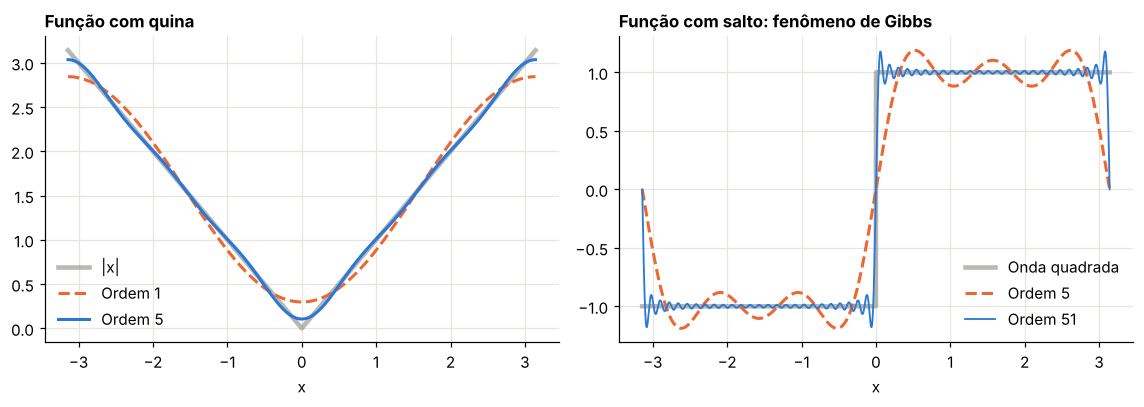

,Ordem,Erro máximo: |x|,Pico acima de 1 na onda quadrada
0,5,"0,105","0,188"
1,25,"0,024","0,179"
2,125,"0,005","0,179"
3,625,"0,001","0,175"


OK — a série converge uniformemente na função com quina
OK — na função com salto, o pico não some ao aumentar a ordem


In [4]:
x = np.linspace(-np.pi, np.pi, 8001)


def serie_abs(x, n):
    soma = np.full_like(x, np.pi / 2)
    for m in range(1, n + 1):
        soma += 2 * ((-1) ** m - 1) / (np.pi * m**2) * np.cos(m * x)
    return soma


def serie_quad(x, n):
    soma = np.zeros_like(x)
    for m in range(1, n + 1, 2):
        soma += 4 / (np.pi * m) * np.sin(m * x)
    return soma


fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.8))
a1.plot(x, np.abs(x), color=CINZA, lw=3, alpha=0.6, label="|x|")
a1.plot(x, serie_abs(x, 1), color=LARANJA, ls="--", label="Ordem 1")
a1.plot(x, serie_abs(x, 5), color=AZUL, label="Ordem 5")
a1.set_title("Função com quina")
a1.set_xlabel("x")
a1.legend()
a2.plot(x, np.sign(x), color=CINZA, lw=3, alpha=0.6, label="Onda quadrada")
a2.plot(x, serie_quad(x, 5), color=LARANJA, ls="--", label="Ordem 5")
a2.plot(x, serie_quad(x, 51), color=AZUL, lw=1.2, label="Ordem 51")
a2.set_title("Função com salto: fenômeno de Gibbs")
a2.set_xlabel("x")
a2.legend(loc="lower right")
plt.tight_layout()
plt.show()

linhas = []
for n in [5, 25, 125, 625]:
    e_abs = np.max(np.abs(serie_abs(x, n) - np.abs(x)))
    e_q = np.max(serie_quad(x, n) - 1)
    linhas.append({"Ordem": n, "Erro máximo: |x|": float(e_abs), "Pico acima de 1 na onda quadrada": float(e_q)})
s_ = pd.DataFrame(linhas)
tabela(s_)
ok(s_["Erro máximo: |x|"].iloc[-1] < s_["Erro máximo: |x|"].iloc[0] / 50, "a série converge uniformemente na função com quina")
ok(s_["Pico acima de 1 na onda quadrada"].iloc[-1] > 0.15, "na função com salto, o pico não some ao aumentar a ordem")

---
## 3. Transformada discreta e FFT

**Livro: §6.5.2 e §6.6.3**

### 3.1 Raízes da unidade

Seja $z_n = e^{-2\pi i/n}$. As potências $z_n^0, z_n^1, \dots, z_n^{n-1}$ são $n$ pontos igualmente espaçados no círculo unitário. Tem-se a soma geométrica:

$$\sum_{j=0}^{n-1}\big(z_n^k\big)^j = \begin{cases}n, & k \equiv 0 \pmod n,\\ 0, & \text{caso contrário.}\end{cases}$$

Prova: se $w = z_n^k \ne 1$, a soma é $(w^n - 1)/(w - 1) = 0$, pois $w^n = 1$. Se $w = 1$, cada termo vale 1. Essa é a **ortogonalidade** que faz tudo funcionar.

### 3.2 A DFT e sua inversa

Dada a sequência $a_0, \dots, a_{n-1}$, sua transformada discreta é

$$b_k = \sum_{j=0}^{n-1}a_j\,z_n^{kj}, \qquad\text{e a inversa,}\qquad a_l = \frac{1}{n}\sum_{k=0}^{n-1}b_k\,z_n^{-lk}.$$

**A prova da inversa** é uma aplicação direta da ortogonalidade: substituindo $b_k$, obtém-se $\frac1n\sum_ja_j\sum_kz_n^{k(j-l)}$, em que a soma interna vale $n$ se $j = l$ e 0 se não.

> **Erratas do livro.** (i) As somas das raízes são escritas a partir de $j = 1$ até $n - 1$; para valerem $0$ ou $n$, devem começar em $j = 0$. (ii) A definição da inversa está sem o fator $1/n$, indispensável, e presente implicitamente nas fórmulas seguintes. (iii) Com $z_n = e^{-2\pi i/n}$, as potências positivas giram em sentido **horário**, e não anti-horário como diz o texto.

### 3.3 Por que é "rápida"

A DFT direta custa $O(n^2)$. O algoritmo de **Cooley-Tukey** usa $n$ par e separa os termos pares e ímpares:

$$b_k = \sum_{j=0}^{n/2-1}a_{2j}\,z_n^{2jk} + z_n^k\sum_{j=0}^{n/2-1}a_{2j+1}\,z_n^{2jk}.$$

Como $z_n^2 = z_{n/2}$, **os dois somatórios são DFTs de tamanho $n/2$**. Além disso, $z_n^{k + n/2} = -z_n^k$, de modo que a segunda metade dos resultados reutiliza os mesmos cálculos. A recursão dá $T(n) = 2T(n/2) + O(n)$, ou seja, $O(n\log n)$.

### Laboratório 3.1 — As três coisas

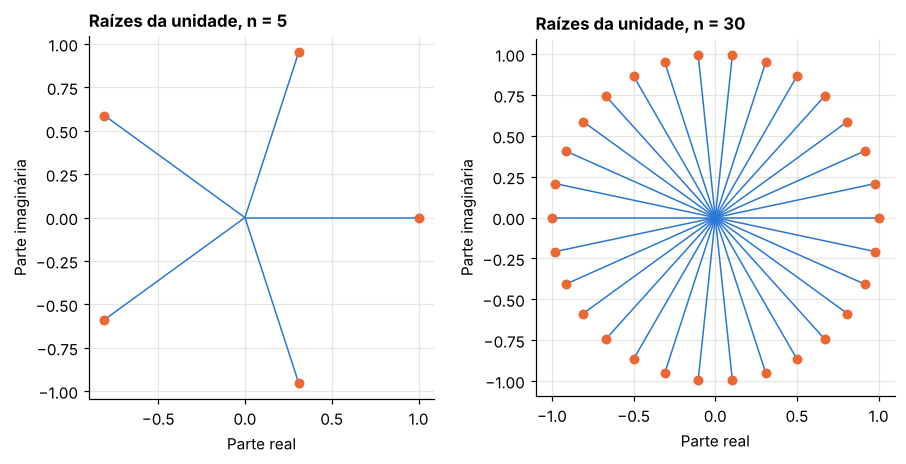

OK — ortogonalidade: a soma vale n para k = 0 e zero nos demais
Soma de j = 1 a n−1, para k = 1 (como no livro): 1,000 (e não 0)
OK — a soma a partir de j = 1 vale 1 em módulo, e não zero
OK — DFT direta, recursiva e numpy coincidem
OK — a inversa, com o fator 1/n, recupera a sequência
OK — sem o fator 1/n, a inversa não recupera a sequência


,n,Direta (ms),FFT em Python (ms),FFT numpy (ms)
0,256,"1,725","1,078","0,022"
1,1024,"43,040","4,069","0,035"
2,4096,"512,657","16,439","0,073"


OK — a FFT é muito mais rápida que a DFT direta


In [5]:
fig, eixos = plt.subplots(1, 2, figsize=(8.4, 4.2))
for ax, n in zip(eixos, [5, 30]):
    z = np.exp(-2j * np.pi * np.arange(n) / n)
    for p in z:
        ax.plot([0, p.real], [0, p.imag], color=AZUL, lw=1)
    ax.scatter(z.real, z.imag, color=LARANJA, s=30, zorder=3)
    ax.set_aspect("equal")
    ax.set_title(f"Raízes da unidade, n = {n}")
    ax.set_xlabel("Parte real")
    ax.set_ylabel("Parte imaginária")
plt.tight_layout()
plt.show()

n = 12
soma_0 = np.sum(np.exp(-2j * np.pi * 0 * np.arange(n) / n))
somas = [abs(np.sum(np.exp(-2j * np.pi * k * np.arange(n) / n))) for k in range(1, n)]
ok(abs(soma_0 - n) < 1e-12 and max(somas) < 1e-12, "ortogonalidade: a soma vale n para k = 0 e zero nos demais")
parcial = abs(np.sum(np.exp(-2j * np.pi * 1 * np.arange(1, n) / n)))
print("Soma de j = 1 a n−1, para k = 1 (como no livro):", f3(float(parcial)), "(e não 0)")
ok(abs(parcial - 1) < 1e-12, "a soma a partir de j = 1 vale 1 em módulo, e não zero")


def dft_direta(a):
    n = a.size
    z = np.exp(-2j * np.pi * np.arange(n)[:, None] * np.arange(n) / n)
    return z @ a


def fft_recursiva(a):
    n = a.size
    if n == 1:
        return a.copy()
    pares, impares = fft_recursiva(a[::2]), fft_recursiva(a[1::2])
    w = np.exp(-2j * np.pi * np.arange(n // 2) / n) * impares
    return np.concatenate([pares + w, pares - w])


rng = np.random.default_rng(901)
a = rng.standard_normal(256) + 1j * rng.standard_normal(256)
ok(np.allclose(dft_direta(a), np.fft.fft(a)) and np.allclose(fft_recursiva(a), np.fft.fft(a)), "DFT direta, recursiva e numpy coincidem")
ok(np.allclose(np.fft.ifft(np.fft.fft(a)), a), "a inversa, com o fator 1/n, recupera a sequência")
ok(not np.allclose(np.fft.ifft(np.fft.fft(a)) * a.size, a), "sem o fator 1/n, a inversa não recupera a sequência")

linhas = []
for n in [256, 1024, 4096]:
    a = rng.standard_normal(n) + 0j
    regs = {}
    for nome, f in [("Direta", dft_direta), ("Recursiva", fft_recursiva), ("numpy", np.fft.fft)]:
        t0 = perf_counter()
        f(a)
        regs[nome] = (perf_counter() - t0) * 1e3
    linhas.append({"n": n, "Direta (ms)": regs["Direta"], "FFT em Python (ms)": regs["Recursiva"], "FFT numpy (ms)": regs["numpy"]})
vel = pd.DataFrame(linhas)
tabela(vel)
ok(vel["FFT numpy (ms)"].iloc[-1] < vel["Direta (ms)"].iloc[-1] / 20, "a FFT é muito mais rápida que a DFT direta")

---
## 4. Precificando uma grade de strikes com FFT

**Livro: §6.5.2 e §6.6.1**

### 4.1 Passo a passo

**Passo 1: discretizar a integral.** Com $v_j = \eta j$, para $j = 0, \dots, N-1$:

$$C(k) \approx \frac{e^{-\alpha k}}{\pi}\sum_{j=0}^{N-1}e^{-iv_jk}\,\psi(v_j)\,\eta.$$

**Passo 2: escolher uma grade de log-strikes.** $k_u = -b + \varepsilon u$, para $u = 0, \dots, N-1$, com $b = \tfrac12N\varepsilon$.

**Passo 3: separar o produto.** $e^{-iv_jk_u} = e^{ibv_j}\,e^{-i\varepsilon\eta ju}$.

**Passo 4: forçar o formato da FFT.** Para que $e^{-i\varepsilon\eta ju} = e^{-2\pi iju/N}$, impomos

$$\varepsilon\,\eta = \frac{2\pi}{N}.$$

**Essa é a restrição de todo o método**: uma grade fina em $v$ (preciso na integral) implica grade grossa em $k$ (poucos strikes úteis), e vice-versa.

**Passo 5: acrescentar pesos de Simpson**, $\tfrac{\eta}{3}\big(3 + (-1)^{j+1} - \delta_{j,0}\big)$, com $j$ a partir de 0, os pesos sendo $1, 4, 2, 4, \dots$. Resulta

$$C(k_u) \approx \frac{e^{-\alpha k_u}}{\pi}\,\text{Re}\sum_{j=0}^{N-1}e^{-2\pi iju/N}\,e^{ibv_j}\,\psi(v_j)\,\frac{\eta}{3}\big(3 + (-1)^{j+1} - \delta_{j,0}\big).$$

### 4.2 Quando usar

O atrativo é ter $N$ preços ao custo de uma FFT. Mas, como o livro observa citando Kahl, as cotações de mercado raramente estão nos pontos da grade. Em calibração, isso acrescenta um erro de interpolação. Em geral, a integração direta (Lewis) é mais adequada; a FFT é mais útil para precificar densidades inteiras.

### Laboratório 4.1 — FFT com os parâmetros do livro

Usamos $N = 4096$ e $\varepsilon = 1/150$, como no livro, que relata cerca de cinco dígitos para a FFT, contra 12 da integração direta. Há uma explicação: o script do livro usa a transformada OTM quando $S_0 < 0{,}95K$, e, como vimos, essa transformada tem cauda lenta. Com $v_{\max} \approx 942$, o erro absoluto fica em torno de $10^{-5}$. Aqui usamos a transformada da call em toda a grade.

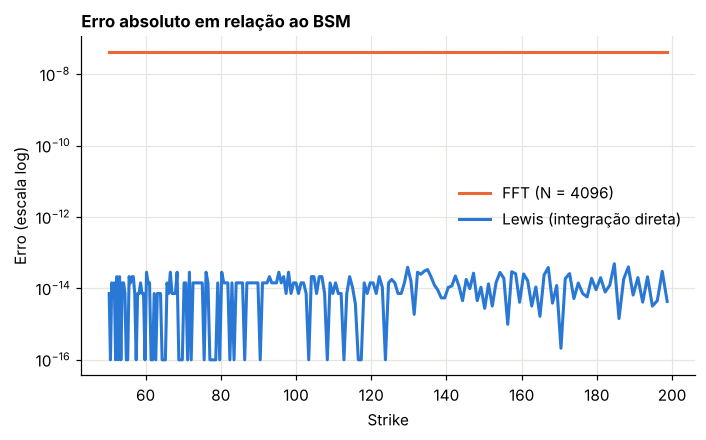

Erro máximo FFT (×10⁶): 0,043 | Erro máximo Lewis (×10⁹): 0,000
Espaçamento da grade de strikes perto do dinheiro: 0,669
OK — com a transformada da call, a FFT supera os cinco dígitos do livro
OK — a integração direta é muito mais precisa


In [6]:
def cm_fft(S, T, r, cf, alpha=1.5, N=4096, eps=1 / 150, k_ref=0.0):
    """Devolve grade de strikes e calls. k_ref coloca ln(K/S) = k_ref em u = N/2."""
    eta = 2 * np.pi / (N * eps)
    b = 0.5 * N * eps - k_ref
    j = np.arange(N)
    v = eta * j
    w = v - (alpha + 1) * 1j
    fi = np.exp(1j * w * r * T) * cf(w)
    psi = np.exp(-r * T) * fi / (alpha**2 + alpha - v**2 + 1j * (2 * alpha + 1) * v)
    peso = (3 + (-1.0) ** (j + 1) - (j == 0)) * eta / 3
    y = np.fft.fft(np.exp(1j * b * v) * psi * peso).real
    k = -b + eps * j
    return S * np.exp(k), S * np.exp(-alpha * k) / np.pi * y


Kg, Cg = cm_fft(S0, T0, r0, lambda u: cf_bsm(u, T0, s0))
mascara = (Kg > 50) & (Kg < 200)
er_fft = np.abs(Cg[mascara] - bsm(S0, Kg[mascara], T0, r0, s0))
er_lw = np.abs(lewis(S0, Kg[mascara], T0, r0, lambda u: cf_bsm(u, T0, s0), 400.0, 40001) - bsm(S0, Kg[mascara], T0, r0, s0))

fig, ax = plt.subplots()
ax.semilogy(Kg[mascara], er_fft + 1e-16, color=LARANJA, label="FFT (N = 4096)")
ax.semilogy(Kg[mascara], er_lw + 1e-16, color=AZUL, label="Lewis (integração direta)")
ax.set_title("Erro absoluto em relação ao BSM")
ax.set_xlabel("Strike")
ax.set_ylabel("Erro (escala log)")
ax.legend()
plt.show()

print("Erro máximo FFT (×10⁶):", f3(float(er_fft.max() * 1e6)), "| Erro máximo Lewis (×10⁹):", f3(float(er_lw.max() * 1e9)))
print("Espaçamento da grade de strikes perto do dinheiro:", f3(float(Kg[2049] - Kg[2048])))
ok(er_fft.max() < 1e-6, "com a transformada da call, a FFT supera os cinco dígitos do livro")
ok(er_lw.max() < er_fft.max() / 100, "a integração direta é muito mais precisa")

### Laboratório 4.2 — Interpolação, velocidade e modelo com saltos

In [7]:
K_alvo = np.array([87.3, 94.1, 101.7, 108.2, 119.9])
M76 = dict(sigma=0.15, lam=0.8, mu=-0.12, delta=0.10)
T_m, r_m = 0.5, 0.03
cf_m = lambda u: cf_merton(u, T_m, **M76)


def merton_serie(S, K, T, r, sigma, lam, mu, delta, n_max=60):
    kap = np.exp(mu + 0.5 * delta**2) - 1
    lq = lam * (1 + kap)
    tot = 0.0
    for n in range(n_max):
        sn = np.sqrt(sigma**2 + n * delta**2 / T)
        rn = r - lam * kap + n * np.log1p(kap) / T
        tot = tot + poisson.pmf(n, lq * T) * bsm(S, K, T, rn, sn)
    return tot


ref_m = merton_serie(S0, K_alvo, T_m, r_m, **M76)
Kg, Cg = cm_fft(S0, T_m, r_m, cf_m)
mask = (Kg > 40) & (Kg < 200) & (Cg > 1e-8)
lin = np.exp(np.interp(np.log(K_alvo), np.log(Kg[mask]), np.log(Cg[mask])))
spl = np.exp(CubicSpline(np.log(Kg[mask]), np.log(Cg[mask]))(np.log(K_alvo)))
lw_m = lewis(S0, K_alvo, T_m, r_m, cf_m, 300.0, 30001)
tabela(pd.DataFrame({"Strike": K_alvo, "Série": ref_m, "Lewis: erro (×10⁶)": np.abs(lw_m - ref_m) * 1e6, "FFT, interp. linear: erro (×10⁶)": np.abs(lin - ref_m) * 1e6, "FFT, spline: erro (×10⁶)": np.abs(spl - ref_m) * 1e6}))
ok(np.max(np.abs(spl - ref_m)) < np.max(np.abs(lin - ref_m)) / 2, "spline erra menos que interpolação linear")
ok(np.max(np.abs(lw_m - ref_m)) < np.max(np.abs(spl - ref_m)), "a integração direta não sofre com interpolação")

Km = np.linspace(70, 140, 2000)
t0 = perf_counter(); lewis(S0, Km, T_m, r_m, cf_m, 300.0, 6001); t_l = perf_counter() - t0
t0 = perf_counter(); Kg2, Cg2 = cm_fft(S0, T_m, r_m, cf_m); np.exp(CubicSpline(np.log(Kg2[mask]), np.log(Cg2[mask]))(np.log(Km))); t_f = perf_counter() - t0
K1 = np.array([100.0])
t0 = perf_counter()
for _ in range(50):
    lewis(S0, K1, T_m, r_m, cf_m, 300.0, 6001)
t_l1 = (perf_counter() - t0) / 50
t0 = perf_counter()
for _ in range(50):
    cm_fft(S0, T_m, r_m, cf_m)
t_f1 = (perf_counter() - t0) / 50
tabela(pd.DataFrame([
    {"Tarefa": "1 opção", "Lewis (ms)": t_l1 * 1e3, "FFT (ms)": t_f1 * 1e3},
    {"Tarefa": "2.000 opções", "Lewis (ms)": t_l * 1e3, "FFT (ms)": t_f * 1e3},
]))
ok(t_f < t_l, "para muitas opções, a FFT é mais rápida que a integração vetorial")

,Strike,Série,Lewis: erro (×10⁶),"FFT, interp. linear: erro (×10⁶)","FFT, spline: erro (×10⁶)"
0,"87,300","15,258","0,000","1.612,652","0,005"
1,"94,100","9,971","0,000","712,216","0,040"
2,"101,700","5,356","0,000","1.244,798","0,048"
3,"108,200","2,730","0,000","447,894","0,045"
4,"119,900","0,577","0,000","132,917","0,044"


OK — spline erra menos que interpolação linear
OK — a integração direta não sofre com interpolação


,Tarefa,Lewis (ms),FFT (ms)
0,1 opção,"0,570","0,568"
1,2.000 opções,"404,433","1,253"


OK — para muitas opções, a FFT é mais rápida que a integração vetorial


---
## 5. A árvore binomial como convolução

**Livro: §6.6.3**

Para ver o que acontece "por dentro" do método, voltamos à árvore do Módulo 6.

### 5.1 O passo para trás é uma convolução

A **convolução circular** de $a$ e $b$ é $c_j = \sum_ka_{(j-k)\bmod n}\,b_k$. Definindo o vetor de probabilidades $qv = (q, 1-q, 0, \dots, 0)$ e seu reverso $\text{rev}(qv) = (q, 0, \dots, 0, 1-q)$:

$$(C\circ\text{rev}(qv))_j = C_j\,q + C_{j+1}\,(1-q),$$

em que o índice crescente desce na árvore. É o passo CRR. O termo circular só contamina as posições da base, inválidas naquela data, e nunca chega à raiz em $M$ passos.

### 5.2 A DFT diagonaliza a convolução

A propriedade é análoga à do caso contínuo: $\mathcal{F}(a\circ b) = \mathcal{F}(a)\cdot\mathcal{F}(b)$, produto termo a termo. $M$ convoluções viram **uma potência**:

$$C_0 = e^{-rT}\,\mathcal{F}^{-1}\Big[\mathcal{F}(C_T)\cdot\mathcal{F}\big(\text{rev}(qv)\big)^M\Big].$$

> **Errata do livro:** o exemplo do método usa $qv = (0{,}5034;\ 0{,}4966;\ 0;\ 0;\ 0)$, embora a Tabela 5.1 e a própria conta na §5.4 tenham $q = 0{,}5378$. Com o vetor impresso, o valor não seria 9,97.

### Laboratório 5.1 — O passo a passo e a fórmula fechada

In [8]:
def params_crr(T, r, sig, M):
    dt = T / M
    u = np.exp(sig * np.sqrt(dt))
    d = 1 / u
    return dt, u, d, (np.exp(r * dt) - d) / (u - d)


def circular(a, b):
    n = a.size
    return np.array([sum(a[(j - k) % n] * b[k] for k in range(n)) for j in range(n)])


def rev(a):
    return np.r_[a[0], a[:0:-1]]


M = 4
dt, u, d, q = params_crr(T0, r0, s0, M)
C = np.maximum(S0 * u ** np.arange(M, -1, -1) * d ** np.arange(M + 1) - K0, 0.0)
qv = np.r_[q, 1 - q, np.zeros(M - 1)]
qv_livro = np.r_[0.5034, 0.4966, np.zeros(M - 1)]
Cl = C.copy()
for _ in range(M):
    C = np.exp(-r0 * dt) * circular(C, rev(qv))
    Cl = np.exp(-r0 * dt) * circular(Cl, rev(qv_livro))
print("q da árvore:", f3(float(q)), "| Valor pela convolução:", f3(float(C[0])), "| Com o vetor impresso no livro:", f3(float(Cl[0])))
ok(abs(C[0] - 9.97) < 0.005, "a convolução reproduz o valor da Tabela 5.1")
ok(abs(Cl[0] - 9.97) > 0.2, "o vetor impresso no livro não reproduz o valor")

a = np.array([1.0, 2.0, 3.0, 4.0])
b = np.array([0.5, -1.0, 2.0, 0.25])
ok(np.allclose(np.fft.fft(circular(a, b)), np.fft.fft(a) * np.fft.fft(b)), "a DFT transforma convolução em produto")


def crr_dft(S0, K, T, r, sig, M, cortar=None):
    """Árvore por DFT. 'cortar' zera os nós acima de S0·exp(cortar·σ√T)."""
    dt, u, d, q = params_crr(T, r, sig, M)
    ST = S0 * u ** np.arange(M, -1, -1) * d ** np.arange(M + 1)
    C = np.maximum(ST - K, 0.0)
    if cortar is not None:
        C[ST > S0 * np.exp(cortar * sig * np.sqrt(T))] = 0.0
    qv = np.zeros(M + 1)
    qv[:2] = q, 1 - q
    return float(np.exp(-r * T) * np.fft.ifft(np.fft.fft(C) * np.fft.fft(rev(qv)) ** M)[0].real)


def crr_dft2(S0, K, T, r, sig, M):
    """Forma alternativa do livro: C0 = F(exp(-rT) · F^{-1}(C_T) · F(qv)^M)."""
    dt, u, d, q = params_crr(T, r, sig, M)
    C = np.maximum(S0 * u ** np.arange(M, -1, -1) * d ** np.arange(M + 1) - K, 0.0)
    qv = np.zeros(M + 1)
    qv[:2] = q, 1 - q
    return float(np.fft.fft(np.exp(-r * T) * np.fft.ifft(C) * np.fft.fft(qv) ** M)[0].real)


def crr_vetor(S0, K, T, r, sig, M):
    dt, u, d, q = params_crr(T, r, sig, M)
    V = np.maximum(S0 * u ** np.arange(M, -1, -1) * d ** np.arange(M + 1) - K, 0.0)
    desc = np.exp(-r * dt)
    for _ in range(M):
        V = desc * (q * V[:-1] + (1 - q) * V[1:])
    return float(V[0])


linhas = []
for M in [500, 5000, 20000]:
    t0 = perf_counter(); v1 = crr_dft(S0, K0, T0, r0, s0, M); t1 = perf_counter() - t0
    t0 = perf_counter(); v2 = crr_dft2(S0, K0, T0, r0, s0, M); t2 = perf_counter() - t0
    t0 = perf_counter(); v3 = crr_vetor(S0, K0, T0, r0, s0, M); t3 = perf_counter() - t0
    v4 = crr_dft(S0, K0, T0, r0, s0, M, cortar=10.0)
    ST_max = S0 * params_crr(T0, r0, s0, M)[1] ** M
    linhas.append({"M": M, "Maior nó final": ST_max, "DFT": v1, "DFT, forma alternativa": v2, "Árvore vetorizada": v3, "DFT cortando extremos": v4, "Erro DFT": abs(v1 - v3), "Erro DFT cortando": abs(v4 - v3), "DFT (ms)": t1 * 1e3, "Árvore (ms)": t3 * 1e3})
d_ = pd.DataFrame(linhas)
tabela(d_)
ok(d_["Erro DFT"].iloc[0] < 1e-8 and abs(d_["DFT"].iloc[0] - d_["DFT, forma alternativa"].iloc[0]) < 1e-8, "para M moderado, as duas formas com DFT coincidem com a árvore")
ok(d_["Erro DFT"].iloc[-1] > 1, "para M muito grande, a DFT direta perde toda a precisão")
ok((d_["Erro DFT cortando"] < 1e-7).all(), "cortando os nós extremos, a precisão volta")
ok(d_["DFT (ms)"].iloc[-1] < d_["Árvore (ms)"].iloc[-1], "para M grande, a DFT é mais rápida que a árvore vetorizada")

q da árvore: 0,538 | Valor pela convolução: 9,971 | Com o vetor impresso no livro: 8,341
OK — a convolução reproduz o valor da Tabela 5.1
OK — o vetor impresso no livro não reproduz o valor
OK — a DFT transforma convolução em produto


,M,Maior nó final,DFT,"DFT, forma alternativa",Árvore vetorizada,DFT cortando extremos,Erro DFT,Erro DFT cortando,DFT (ms),Árvore (ms)
0,500,"8.754,351","10,447","10,447","10,447","10,447","0,000","0,000","0,565","1,267"
1,5000,"138.628.161,529","10,450","10,450","10,450","10,450","0,000","0,000","1,625","34,901"
2,20000,"192.177.671.690.278,062","34,602","13,728","10,450","10,450","24,152","0,000","4,957","902,205"


OK — para M moderado, as duas formas com DFT coincidem com a árvore
OK — para M muito grande, a DFT direta perde toda a precisão
OK — cortando os nós extremos, a precisão volta
OK — para M grande, a DFT é mais rápida que a árvore vetorizada


**Cuidado numérico.** Com $M = 20.000$, o maior nó da árvore está na casa de $10^{12}$. A FFT mistura todas as entradas em cada coeficiente, e o erro de arredondamento é proporcional à **maior** delas. Ele contamina o valor que queremos. A árvore direta não sofre desse problema, porque os nós extremos só afetam os vizinhos. A correção é zerar nós irrelevantes: o que está acima de 10 desvios-padrão contribui com um valor desprezível.

---
## 6. Qual método usar?

| Método | Vantagem | Limitação | Uso natural |
|---|---|---|---|
| **Lewis** (integração direta) | Precisão e simplicidade; strikes arbitrários | Caudas exigem cuidado | Calibração |
| **Carr-Madan com FFT** | Grade inteira ao custo de uma FFT | Interpolação; acoplamento entre grades | Densidades, grandes malhas |
| **Carr-Madan com $\alpha$ por strike** | Erro relativo pequeno nas caudas | Uma integral por strike | Opções muito fora do dinheiro |
| **Transformada OTM** | Sem subtrair $S_0$ | Cauda lenta; singular em $k = 0$ | Grades de FFT muito longas |
| **FFT na árvore** | Instrutivo | Não serve para americanas; a soma binomial já é $O(M)$ | Ensino |

Uma observação final, em nome da honestidade do método: no Módulo 6, a soma binomial fechada já custa $O(M)$. A FFT na árvore, de custo $O(M\log M)$, é mais lenta que ela. O interesse do exemplo é mostrar a estrutura, e não ganhar tempo.

---
## 7. Síntese

- Carr-Madan é a fórmula de Lewis antes de atravessar o polo, com $u_i = \alpha + 1$.
- $\alpha$ muito pequeno ou muito grande estraga a precisão.
- Nas caudas, escolher $\alpha$ por strike é melhor que a transformada do valor no tempo, que tem cauda lenta.
- A regularidade determina a velocidade de convergência, o que vale para séries e para árvores.
- A DFT se apoia na ortogonalidade das raízes da unidade, e a FFT reduz seu custo para $O(n\log n)$.
- A restrição $\varepsilon\eta = 2\pi/N$ é o preço da FFT.
- Na árvore, o passo para trás é uma convolução, e a DFT a transforma em potência; para muitos passos, é preciso controlar a amplitude dos dados.

## 8. Notas sobre o livro neste trecho

| Local | Problema |
|---|---|
| §6.5.1 | $e^{iux}$ está expandida incorretamente: o fator é $e^{-u_ix}$ e a oscilação usa apenas $u_r$ |
| Def. 43 | as somas de potências devem começar em $j = 0$ |
| Def. 43 | potências positivas de $z_n$ giram em sentido horário |
| Def. 44 | a inversa da DFT precisa do fator $1/n$ |
| §6.6.2, equação (6.13) | a lei $\ln(1+J) \sim N(\ln(1+\mu_J) - \delta^2/2, \delta^2)$ não é compatível com $r_J = \lambda(e^{\mu_J + \delta^2/2} - 1)$ e com (6.14), que correspondem a $\ln(1+J) \sim N(\mu_J, \delta^2)$ |
| §6.6.3 | o vetor $qv = (0{,}5034;\ 0{,}4966; \dots)$ é incompatível com $q = 0{,}5378$ |
| Equação (6.6) | falta tomar a parte real |
| §6.6.1, precisão da FFT | os cinco dígitos relatados vêm do ramo OTM do script, de cauda lenta; não são um limite da FFT |

## 9. Exercícios

**Exercício 1.** Com $N = 4096$ e $\varepsilon = 1/150$, qual é o maior limite de integração $v_{\max}$?

<details><summary>Solução</summary>

$\eta = 2\pi/(N\varepsilon) = 0{,}230$. Logo, $v_{\max} = \eta N = 2\pi/\varepsilon = 942{,}478$.
</details>

**Exercício 2.** Mostre que $\mathcal{F}(a\circ b) = \mathcal{F}(a)\mathcal{F}(b)$.

<details><summary>Solução</summary>

$\sum_jz^{kj}\sum_la_{j-l}b_l = \sum_lb_lz^{kl}\sum_ja_{j-l}z^{k(j-l)} = \mathcal{F}(b)_k\,\mathcal{F}(a)_k$, usando a periodicidade de $z^{kj}$ em $j$.
</details>

**Exercício 3.** Em Carr-Madan, por que $\alpha$ precisa ser positivo? O que acontece com a put se $\alpha < -1$?

<details><summary>Solução</summary>

Com $\alpha > 0$, a função $e^{\alpha k}C(k)$ vai a zero em $k \to -\infty$, onde $C \to S_0$. Com $\alpha < -1$, o amortecimento favorece $k \to +\infty$ e a integral fica associada à put, de modo análogo ao que vimos ao mudar de faixa na integral de Lewis.
</details>

**Exercício 4.** Por que a FFT não serve diretamente para a árvore de uma opção americana?

<details><summary>Solução</summary>

O `max` entre continuação e exercício é uma operação não linear, aplicada a cada data. Não se pode juntar todos os passos em uma potência, que só vale para operadores lineares.
</details>

In [9]:
print(f"Módulo 8 concluído: {_checks['n']} verificações aprovadas.")

Módulo 8 concluído: 26 verificações aprovadas.
